# Stage 0 — Two-node GNW Mean-Field CTC Setup

This notebook creates the S→W simulation foundation before the Stage 1 CTC controls. Both nodes use the **same E/I population-rate and synaptic-state update function as the 40-area GNW model**. Each node also has a phase variable so rate-based response and phase synchrony can be read separately.

- **S (sensory/source)** receives the external stimulus.
- **W (workspace/target)** receives a directed S→W rate input and is checked for sustained activity.
- `r_S(t)` and `r_W(t)` are excitatory population rates in Hz; each node also carries local inhibitory rate and E/I synaptic states internally.
- `theta_S(t)` and `theta_W(t)` are added phase oscillators. The original GNW mean-field model does not include phase, so phase evolution is kept as a separate extension.

The S→W rate gain and phase parameters are provisional. This step checks the wiring and outputs; it does not claim CTC validation.

## Step 1 — load the shared model interface

`gnw_mean_field.py` contains the reusable GNW transfer curve, initialization, and one-step E/I update. The 40-area notebook has been changed to call this same interface, so this two-node simulation does not substitute a separate rate equation.

In [5]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'gnw_mean_field.py').exists()), None
)
if project_root is None:
    raise RuntimeError('Run Jupyter from the project root or a subfolder.')
experiment_dir = project_root / 'project_experiment'
sys.path.insert(0, str(project_root))
sys.path.insert(0, str(experiment_dir))

from gnw_mean_field import GNWMeanFieldParameters, mean_field_step
from stage0_two_node import DEFAULTS, simulate_stage0

print('Shared GNW mean-field parameters:')
print(GNWMeanFieldParameters())

Shared GNW mean-field parameters:
GNWMeanFieldParameters(rE_max_hz=80.0, rI_max_hz=60.0, tau_E_ms=10.0, tau_I_ms=8.0, tau_sE_ms=8.0, tau_sI_ms=8.0, theta_E=0.3, slope_E=0.12, theta_I=0.6, slope_I=0.12, J_EI=1.2, J_IE=0.8, J_II=0.3)


## Step 2 — define S, W, stimulus, and rate/phase settings

The E/I transfer curves, time constants, and coupling balance below default to the working values in the 40-area GNW notebook. Stage 0 uses one directed S→W edge instead of the full anatomical matrix. The phase gate is off at first so the baseline shows the rate and phase readouts without phase changing the rate connection.

In [6]:
stage0_params = dict(DEFAULTS)
# Example semantic labels. Replace these if the experiment chooses concrete areas.
source_label = 'S (sensory/source)'
workspace_label = 'W (workspace/target)'
print(f'{source_label} → {workspace_label}')
print(f"GNW mean-field dt: {stage0_params['dt_ms']} ms")
print(f"Stimulus: {stage0_params['stim_on_ms']}–{stage0_params['stim_off_ms']} ms")
print(f"S→W rate gain: {stage0_params['g_sw']}; phase gate: {stage0_params['phase_gate_strength']}")
print('The phase oscillator is an added state; it is not part of the original GNW rate interface.')

S (sensory/source) → W (workspace/target)
GNW mean-field dt: 1.0 ms
Stimulus: 50.0–500.0 ms
S→W rate gain: 0.95; phase gate: 0.0
The phase oscillator is an added state; it is not part of the original GNW rate interface.


## Step 3 — run the two-node baseline

Run A as the baseline with a directed S→W rate projection. B and C are included as wiring checks for the upcoming Stage 1 controls. The `phase_gate_strength` default is zero in this setup.

In [7]:
baseline = simulate_stage0('A', seed=1, params=stage0_params)
common_drive_control = simulate_stage0('B', seed=1, params=stage0_params)
one_way_phase_control = simulate_stage0('C', seed=1, params=stage0_params)

runs = {
    'A: coupled phases + S→W rate link': baseline,
    'B: common rhythm, rate link off': common_drive_control,
    'C: one-way phase drag + S→W rate link': one_way_phase_control,
}
summary = pd.DataFrame([
    {
        'condition': label,
        'peak_S_rate_hz': run['r_s_hz'].max(),
        'peak_W_rate_hz': run['r_w_hz'].max(),
        'global_PLV_during_stimulus': abs(np.exp(1j * (
            run['theta_w_rad'][(run['time_ms'] >= stage0_params['stim_on_ms']) &
                               (run['time_ms'] < stage0_params['stim_off_ms'])]
            - run['theta_s_rad'][(run['time_ms'] >= stage0_params['stim_on_ms']) &
                                 (run['time_ms'] < stage0_params['stim_off_ms'])]
        )).mean()),
        'W_ignited_20Hz_50ms': run['ignited'],
        'W_latency_ms': run['ignition_latency_ms'],
    }
    for label, run in runs.items()
])
display(summary)

,condition,peak_S_rate_hz,peak_W_rate_hz,global_PLV_during_stimulus,W_ignited_20Hz_50ms,W_latency_ms
0,A: coupled phases + S→W rate link,20.872712,25.933532,0.934810,True,92.0
1,"B: common rhythm, rate link off",20.872712,6.068654,0.946509,False,NaN
2,C: one-way phase drag + S→W rate link,20.872712,25.933532,0.994068,True,92.0


## Step 4 — inspect rates and phases

Rates answer whether activity reaches W and remains above the selected response criterion. Phase difference and rolling PLV answer whether S and W are synchronized. They are separate outputs here.

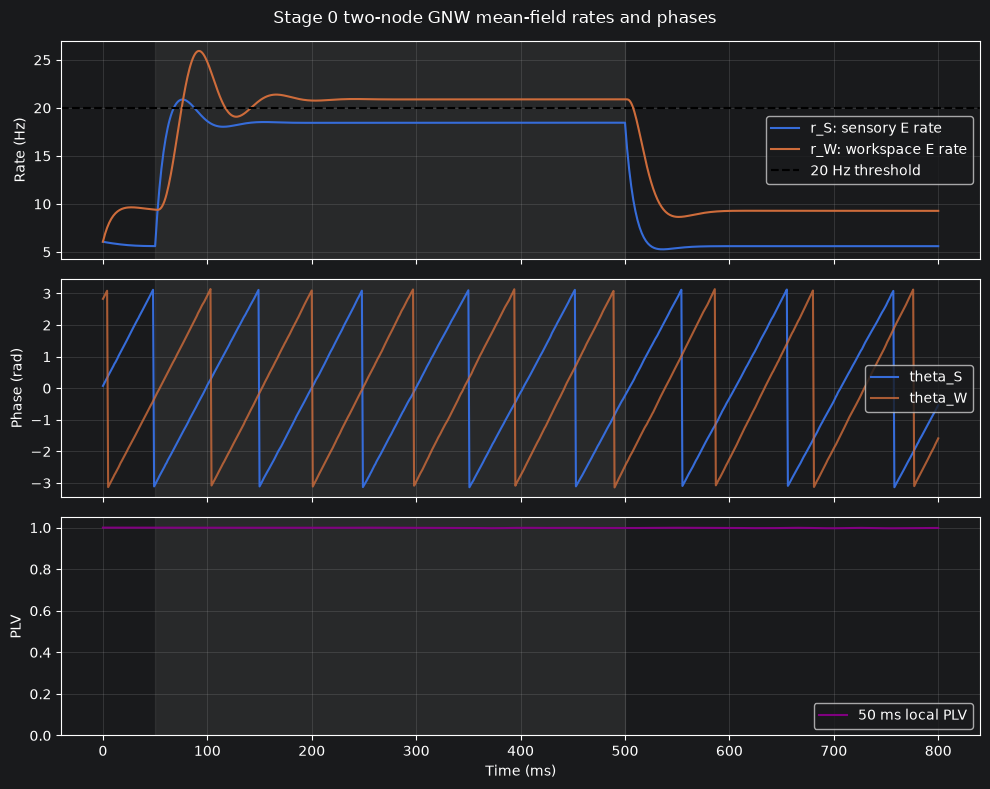

In [8]:
run = baseline
t_ms = run['time_ms']
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(t_ms, run['r_s_hz'], label='r_S: sensory E rate')
axes[0].plot(t_ms, run['r_w_hz'], label='r_W: workspace E rate')
axes[0].axhline(stage0_params['ignition_threshold_hz'], color='black', ls='--', label='20 Hz threshold')
axes[0].set_ylabel('Rate (Hz)'); axes[0].legend(); axes[0].grid(alpha=.25)
axes[1].plot(t_ms, run['theta_s_rad'], label='theta_S')
axes[1].plot(t_ms, run['theta_w_rad'], label='theta_W', alpha=.8)
axes[1].set_ylabel('Phase (rad)'); axes[1].legend(); axes[1].grid(alpha=.25)
axes[2].plot(t_ms, run['phase_locking_value'], color='purple', label='50 ms local PLV')
axes[2].set_ylabel('PLV'); axes[2].set_xlabel('Time (ms)'); axes[2].set_ylim(0, 1.05)
axes[2].legend(); axes[2].grid(alpha=.25)
for ax in axes: ax.axvspan(stage0_params['stim_on_ms'], stage0_params['stim_off_ms'], color='gray', alpha=.15)
plt.suptitle('Stage 0 two-node GNW mean-field rates and phases')
plt.tight_layout(); plt.show()

## Step 5 — paired A/B/C parameter scan

The first five-seed screen at the default drive (0.20) made A/C ignite in every trial, so it was too close to a ceiling. This scan uses a provisional lower sensory drive (0.12; `g_sw=0.95`) to retain a transition region. A separate screen should be rerun if you change the transfer curve or stimulus.

The scan varies phase coupling `K`, gate strength, and condition with paired seeds. PLV `R` is computed over the **whole stimulus interval**, not averaged from the 50 ms local PLV trace; the short local window is biased toward 1 for 10 Hz oscillations. For A/C with nonzero gate, the scan also runs a fixed-weight control whose S→W gain matches that trial's mean gated gain during stimulation. B is run once per K/seed because its S→W rate path is cut.

The cell defaults to a 5-seed pilot. After inspecting it, set `RUN_FULL_SCAN = True` for 30 paired seeds.

In [9]:
coupling_grid = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]  # rad/s
gate_grid = [0.0, 0.25, 0.5, 0.75]
all_seeds = list(range(1, 31))
RUN_FULL_SCAN = False  # change to True after the pilot looks sensible
scan_seeds = all_seeds if RUN_FULL_SCAN else all_seeds[:5]
scan_base_params = {**stage0_params, 'stimulus_drive': 0.12, 'g_sw': 0.95}
try:
    from tqdm.auto import tqdm
    total_scan_runs = len(coupling_grid) * len(scan_seeds) * (1 + 2 * (len(gate_grid) + len(gate_grid) - 1))
    scan_progress = tqdm(total=total_scan_runs, desc='Stage 0 paired scan', unit='run')
except ImportError:
    scan_progress = None
scan_rows = []
stim_mask = (baseline['time_ms'] >= scan_base_params['stim_on_ms']) & (baseline['time_ms'] < scan_base_params['stim_off_ms'])

def _scan_record(result, comparison, coupling, gate, seed):
    during = (result['time_ms'] >= scan_base_params['stim_on_ms']) & (result['time_ms'] < scan_base_params['stim_off_ms'])
    after = result['time_ms'] >= scan_base_params['stim_off_ms']
    return {
        'comparison': comparison, 'K_rad_s': coupling, 'gate_strength': gate, 'seed': int(seed),
        'mean_PLV_during_stim': float(abs(np.exp(1j * (result['theta_w_rad'][during] - result['theta_s_rad'][during])).mean())),
        'mean_local_PLV_50ms': float(result['phase_locking_value'][during].mean()),
        'W_ignited': bool(result['ignited']), 'W_latency_ms': result['ignition_latency_ms'],
        'mean_W_rate_during_hz': float(result['r_w_hz'][during].mean()),
        'mean_W_rate_after_stim_hz': float(result['r_w_hz'][after].mean()),
        'max_W_rate_hz': float(result['r_w_hz'].max()),
        'mean_S_to_W_gain_during': float(result['g_sw_effective'][during].mean()),
    }

for coupling in coupling_grid:
    for seed in scan_seeds:
        # Shared-rhythm control: no rate link, so it is independent of gate strength.
        b_params = {**scan_base_params, 'phase_coupling_rad_s': coupling, 'phase_gate_strength': 0.0}
        b_run = simulate_stage0('B', seed=seed, params=b_params)
        if scan_progress is not None: scan_progress.update(1)
        scan_rows.append(_scan_record(b_run, 'B_common_drive_no_link', coupling, 0.0, seed))

        for condition in ('A', 'C'):
            for gate in gate_grid:
                dynamic_params = {**scan_base_params, 'phase_coupling_rad_s': coupling, 'phase_gate_strength': gate}
                dynamic_run = simulate_stage0(condition, seed=seed, params=dynamic_params)
                if scan_progress is not None: scan_progress.update(1)
                scan_rows.append(_scan_record(dynamic_run, f'{condition}_dynamic_gate', coupling, gate, seed))

                # Match the time-averaged S→W gain to isolate dynamic gating from mean-strength changes.
                if gate > 0:
                    matched_gain = float(dynamic_run['g_sw_effective'][stim_mask].mean())
                    matched_params = {**scan_base_params, 'phase_coupling_rad_s': coupling,
                                      'phase_gate_strength': 0.0, 'g_sw': matched_gain}
                    matched_run = simulate_stage0(condition, seed=seed, params=matched_params)
                    if scan_progress is not None: scan_progress.update(1)
                    scan_rows.append(_scan_record(matched_run, f'{condition}_mean_matched_fixed',
                                                  coupling, gate, seed))

if scan_progress is not None: scan_progress.close()
scan_results = pd.DataFrame(scan_rows)
scan_summary = scan_results.groupby(['comparison', 'K_rad_s', 'gate_strength'], dropna=False).agg(
    n=('seed', 'count'),
    W_ignition_probability=('W_ignited', 'mean'),
    mean_PLV=('mean_PLV_during_stim', 'mean'),
    mean_W_during_hz=('mean_W_rate_during_hz', 'mean'),
    mean_W_after_hz=('mean_W_rate_after_stim_hz', 'mean'),
    mean_peak_W_hz=('max_W_rate_hz', 'mean'),
).reset_index()
print(f"Completed {len(scan_results)} runs using {len(scan_seeds)} paired seeds.")
display(scan_summary.round(3))

# Paired seed-level differences with bootstrap 95% intervals.
_boot_rng = np.random.default_rng(20261122)
def _paired_bootstrap_ci(values, n_boot=2000):
    values = np.asarray(values, dtype=float)
    draws = _boot_rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return float(values.mean()), float(np.quantile(draws, 0.025)), float(np.quantile(draws, 0.975))

contrast_rows = []
for condition in ('A', 'C'):
    for coupling in coupling_grid:
        for gate in gate_grid:
            if gate == 0:
                continue
            treatment = scan_results[
                (scan_results['comparison'] == f'{condition}_dynamic_gate')
                & (scan_results['K_rad_s'] == coupling)
                & (scan_results['gate_strength'] == gate)
            ].set_index('seed')
            matched = scan_results[
                (scan_results['comparison'] == f'{condition}_mean_matched_fixed')
                & (scan_results['K_rad_s'] == coupling)
                & (scan_results['gate_strength'] == gate)
            ].set_index('seed')
            paired = treatment[['W_ignited', 'mean_W_rate_after_stim_hz']].join(
                matched[['W_ignited', 'mean_W_rate_after_stim_hz']],
                lsuffix='_dynamic', rsuffix='_matched', how='inner')
            for metric, label in (('W_ignited', 'ignition_probability_difference'),
                                  ('mean_W_rate_after_stim_hz', 'late_W_rate_difference_hz')):
                mean, low, high = _paired_bootstrap_ci(
                    paired[f'{metric}_dynamic'].astype(float).to_numpy()
                    - paired[f'{metric}_matched'].astype(float).to_numpy())
                contrast_rows.append({'comparison': f'{condition}_dynamic_minus_mean_matched',
                                      'K_rad_s': coupling, 'gate_strength': gate,
                                      'outcome': label, 'paired_mean_difference': mean,
                                      'bootstrap_95ci_low': low, 'bootstrap_95ci_high': high,
                                      'n_pairs': len(paired)})
paired_contrasts = pd.DataFrame(contrast_rows)
print('Paired dynamic-gate minus mean-matched fixed-weight contrasts:')
display(paired_contrasts.round(3))

# Keep trial-level data for paired confidence intervals; save locally when ready.
# scan_results.to_csv(project_root / 'project_experiment' / 'stage0_scan_trials.csv', index=False)
# scan_summary.to_csv(project_root / 'project_experiment' / 'stage0_scan_summary.csv', index=False)

Stage 0 paired scan:   0%|          | 0/450 [00:00<?, ?run/s]

Completed 450 runs using 5 paired seeds.


,comparison,K_rad_s,gate_strength,n,W_ignition_probability,mean_PLV,mean_W_during_hz,mean_W_after_hz,mean_peak_W_hz
0,A_dynamic_gate,0.0,0.00,5,0.0,0.964,14.961,9.680,16.129
1,A_dynamic_gate,0.0,0.25,5,0.0,0.964,16.466,10.213,18.221
2,A_dynamic_gate,0.0,0.50,5,0.4,0.964,17.968,10.757,20.651
3,A_dynamic_gate,0.0,0.75,5,0.6,0.964,19.430,11.310,23.195
4,A_dynamic_gate,0.5,0.00,5,0.0,0.966,14.961,9.680,16.129
...,...,...,...,...,...,...,...,...,...
85,C_mean_matched_fixed,2.0,0.50,5,0.6,0.992,18.644,11.191,21.000
86,C_mean_matched_fixed,2.0,0.75,5,0.6,0.992,20.416,11.978,23.587
87,C_mean_matched_fixed,3.0,0.25,5,0.0,0.979,16.933,10.473,18.645
88,C_mean_matched_fixed,3.0,0.50,5,0.6,0.979,18.895,11.292,21.324


C:\Windows\Temp\ipykernel_36600\3093165340.py:91: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  paired = treatment[['W_ignited', 'mean_W_rate_after_stim_hz']].join(
C:\Windows\Temp\ipykernel_36600\3093165340.py:91: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  paired = treatment[['W_ignited', 'mean_W_rate_after_stim_hz']].join(
C:\Windows\Temp\ipykernel_36600\3093165340.py:91: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  paired = treatment[['W_ignited', 'mean_W_rate_after_stim_hz']].join(
C:\Windows\Temp\ipykernel_36600\3093165340.py:91: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be 

Paired dynamic-gate minus mean-matched fixed-weight contrasts:


C:\Windows\Temp\ipykernel_36600\3093165340.py:91: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  paired = treatment[['W_ignited', 'mean_W_rate_after_stim_hz']].join(
C:\Windows\Temp\ipykernel_36600\3093165340.py:91: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  paired = treatment[['W_ignited', 'mean_W_rate_after_stim_hz']].join(
C:\Windows\Temp\ipykernel_36600\3093165340.py:91: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  paired = treatment[['W_ignited', 'mean_W_rate_after_stim_hz']].join(
C:\Windows\Temp\ipykernel_36600\3093165340.py:91: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be 

,comparison,K_rad_s,gate_strength,outcome,paired_mean_difference,bootstrap_95ci_low,bootstrap_95ci_high,n_pairs
0,A_dynamic_minus_mean_matched,0.0,0.25,ignition_probability_difference,0.000,0.000,0.000,5
1,A_dynamic_minus_mean_matched,0.0,0.25,late_W_rate_difference_hz,-0.072,-0.315,0.219,5
2,A_dynamic_minus_mean_matched,0.0,0.50,ignition_probability_difference,0.000,0.000,0.000,5
3,A_dynamic_minus_mean_matched,0.0,0.50,late_W_rate_difference_hz,-0.151,-0.650,0.350,5
4,A_dynamic_minus_mean_matched,0.0,0.75,ignition_probability_difference,0.200,0.000,0.600,5
...,...,...,...,...,...,...,...,...
67,C_dynamic_minus_mean_matched,3.0,0.25,late_W_rate_difference_hz,0.235,0.016,0.454,5
68,C_dynamic_minus_mean_matched,3.0,0.50,ignition_probability_difference,0.000,0.000,0.000,5
69,C_dynamic_minus_mean_matched,3.0,0.50,late_W_rate_difference_hz,0.484,0.034,0.935,5
70,C_dynamic_minus_mean_matched,3.0,0.75,ignition_probability_difference,0.000,0.000,0.000,5


## Step 6 — plot scan outcomes

Compare ignition probability and PLV across each condition. The mean-matched controls are the key check: if dynamic-gate trials outperform them at similar average connection strength, the result is more consistent with timing-dependent gating than a stronger average pathway. B can show high PLV even though its S→W rate link is absent.

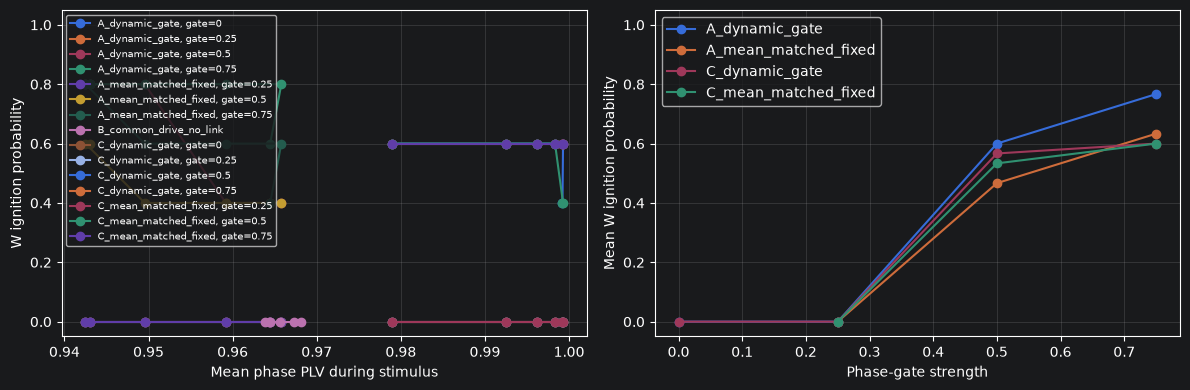

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for comparison, group in scan_summary.groupby('comparison'):
    if comparison == 'B_common_drive_no_link':
        axes[0].plot(group['mean_PLV'], group['W_ignition_probability'], 'o-', label=comparison)
        continue
    for gate, sub in group.groupby('gate_strength'):
        axes[0].plot(sub['mean_PLV'], sub['W_ignition_probability'], 'o-',
                     label=f'{comparison}, gate={gate:g}')
axes[0].set(xlabel='Mean phase PLV during stimulus', ylabel='W ignition probability', ylim=(-0.05, 1.05))
axes[0].grid(alpha=.25); axes[0].legend(fontsize=7)

for comparison, group in scan_summary.groupby('comparison'):
    if comparison == 'B_common_drive_no_link':
        continue
    mean_by_gate = group.groupby('gate_strength')['W_ignition_probability'].mean()
    axes[1].plot(mean_by_gate.index, mean_by_gate.values, 'o-', label=comparison)
axes[1].set(xlabel='Phase-gate strength', ylabel='Mean W ignition probability', ylim=(-0.05, 1.05))
axes[1].grid(alpha=.25); axes[1].legend()
plt.tight_layout(); plt.show()

## Step 7 — what this establishes and what comes next

The notebook now contains the Stage 0 model and a first paired A/B/C scan. Start with the five-seed pilot and inspect the table/plots. If the responses are not saturated and the controls behave as expected, set `RUN_FULL_SCAN = True` and rerun the scan for 30 paired seeds.

A favorable pilot is not final CTC evidence. The next analysis should check paired uncertainty and add a bias-controlled information-transfer measure (MI) before making a communication claim. Keep the 40-area GNW ignition criterion separate from any conclusions about synchrony causality.